# Memahami pipeline possession — dari video sampai submission

Notebook ini menjelaskan **apa yang sebenarnya terjadi** di challenge ini, dengan gambar frame video asli.

| Bagian | Isi |
|---|---|
| 1 | Apa itu "satu baris data" → satu frame video + data tracking-nya |
| 2 | Seperti apa label `H`, `A`, `D` di video |
| 3 | Urutan frame saat possession berpindah (seperti video yang dipotong-potong) |
| 4 | Dari tracking menjadi tabel fitur (ala Kaggle) |
| 5 | Dari mana data latih (train) didapat — pertandingan lain |
| 6 | Kenapa butuh Viterbi (merapikan prediksi) & cara metrik menilai |
| 7 | Klip video mp4 dengan label |

> ⚠️ **Jangan commit notebook ini dengan output-nya ke repo publik.** Output berisi potongan video
> pertandingan yang tidak boleh disebarkan (RULES.md). Sebelum commit: *Clear All Outputs*.

Prasyarat: sudah menjalankan `python -m possession.run` (membuat `evaluation/results/tracking_hmm.csv`).

In [1]:
import os, sys
ROOT = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
sys.path[:0] = [ROOT, os.path.join(ROOT, 'evaluation'), os.path.join(ROOT, 'starter')]
os.chdir(ROOT)

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from possession.data import load_bar_ath, load_metrica_sample, sample_events
from possession import viz
import possession_metrics as pm

plt.rcParams['figure.dpi'] = 110
m = load_bar_ath()                      # tracking BAR-ATH (posisi pemain & bola per frame)
read = lambda p: pd.read_csv(p).label.to_numpy()
gt   = read('evaluation/gt/BAR-ATH_possession_gt_public.csv')     # label benar (5 menit publik)
pred = read('evaluation/results/tracking_hmm.csv')                # prediksi model kita
base = read('evaluation/results/baseline_smooth50.csv')           # baseline resmi
probs = np.load('data/cache/bar_ath_probs.npz')                   # probabilitas per frame
W0, W1 = 11185, 18685                                             # jendela 5 menit publik
print('jumlah frame:', m.n, '| frame dinilai di jendela publik:', W1 - W0)

jumlah frame: 199319 | frame dinilai di jendela publik: 7500


## 1. Satu "baris data" = satu frame video

Video taktis direkam 25 frame/detik → 199.319 frame. **Submission = 1 baris per frame.**

Kita tidak memproses video sendiri. Metrica sudah menjalankan computer vision dan memberikan file
**tracking (ATD)**: untuk tiap frame, posisi setiap pemain (x, y) dan bola. Di bawah ini posisi dari
file tracking itu **digambar di atas frame video** (pakai *homography*: rumus yang memetakan
koordinat lapangan → piksel gambar).

- lingkaran **biru** = pemain Barcelona (home, `H`) · lingkaran **merah** = pemain Athletic (away, `A`)
- titik **kuning** = bola · garis putih = garis lapangan hasil proyeksi

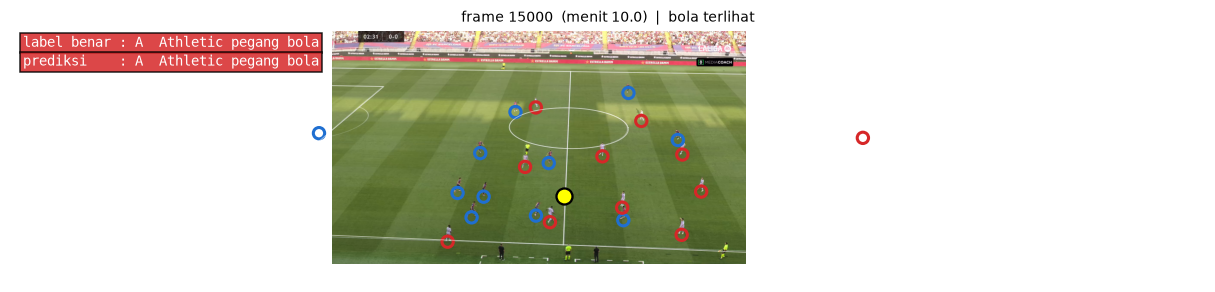

isi mentah file ATD (dipotong): 15001:NaN,NaN,NaN;0.38048,0.84910,2.9335386753082275;0.60284,0.22406,3.845512628555298;0.47091,0.91784,3.3056082725524902;NaN,NaN,NaN;0.65085,0.56984,2.2121760845184326;NaN,NaN,NaN;NaN,NaN,NaN;0.55916,0.92218,4.982807636260986;NaN ...


In [2]:
i = 15000
fig, ax = plt.subplots(figsize=(14, 8))
viz.show_frame(ax, m, i, gt=gt[i], pred=pred[i])
plt.show()

# baris mentah dari file tracking untuk frame yang sama (ATD menghitung dari 1, video dari 0)
with open('data/tactical/BAR-ATH_tactical_atd.txt') as f:
    for k, line in enumerate(f):
        if k == i:
            print('isi mentah file ATD (dipotong):', line[:230], '...')
            break

Itulah satu "baris". Formatnya `frame : pemain1 x,y,kecepatan ; pemain2 ... : bola x,y,kecepatan`,
dengan `NaN` kalau objek tidak terdeteksi. **Targetnya** adalah satu huruf: siapa yang menguasai bola di frame itu.

## 2. Seperti apa label H, A, D?

Diambil otomatis dari jendela 5 menit publik: frame di tengah possession Barcelona terpanjang,
possession Athletic terpanjang, dan bola mati terpanjang.

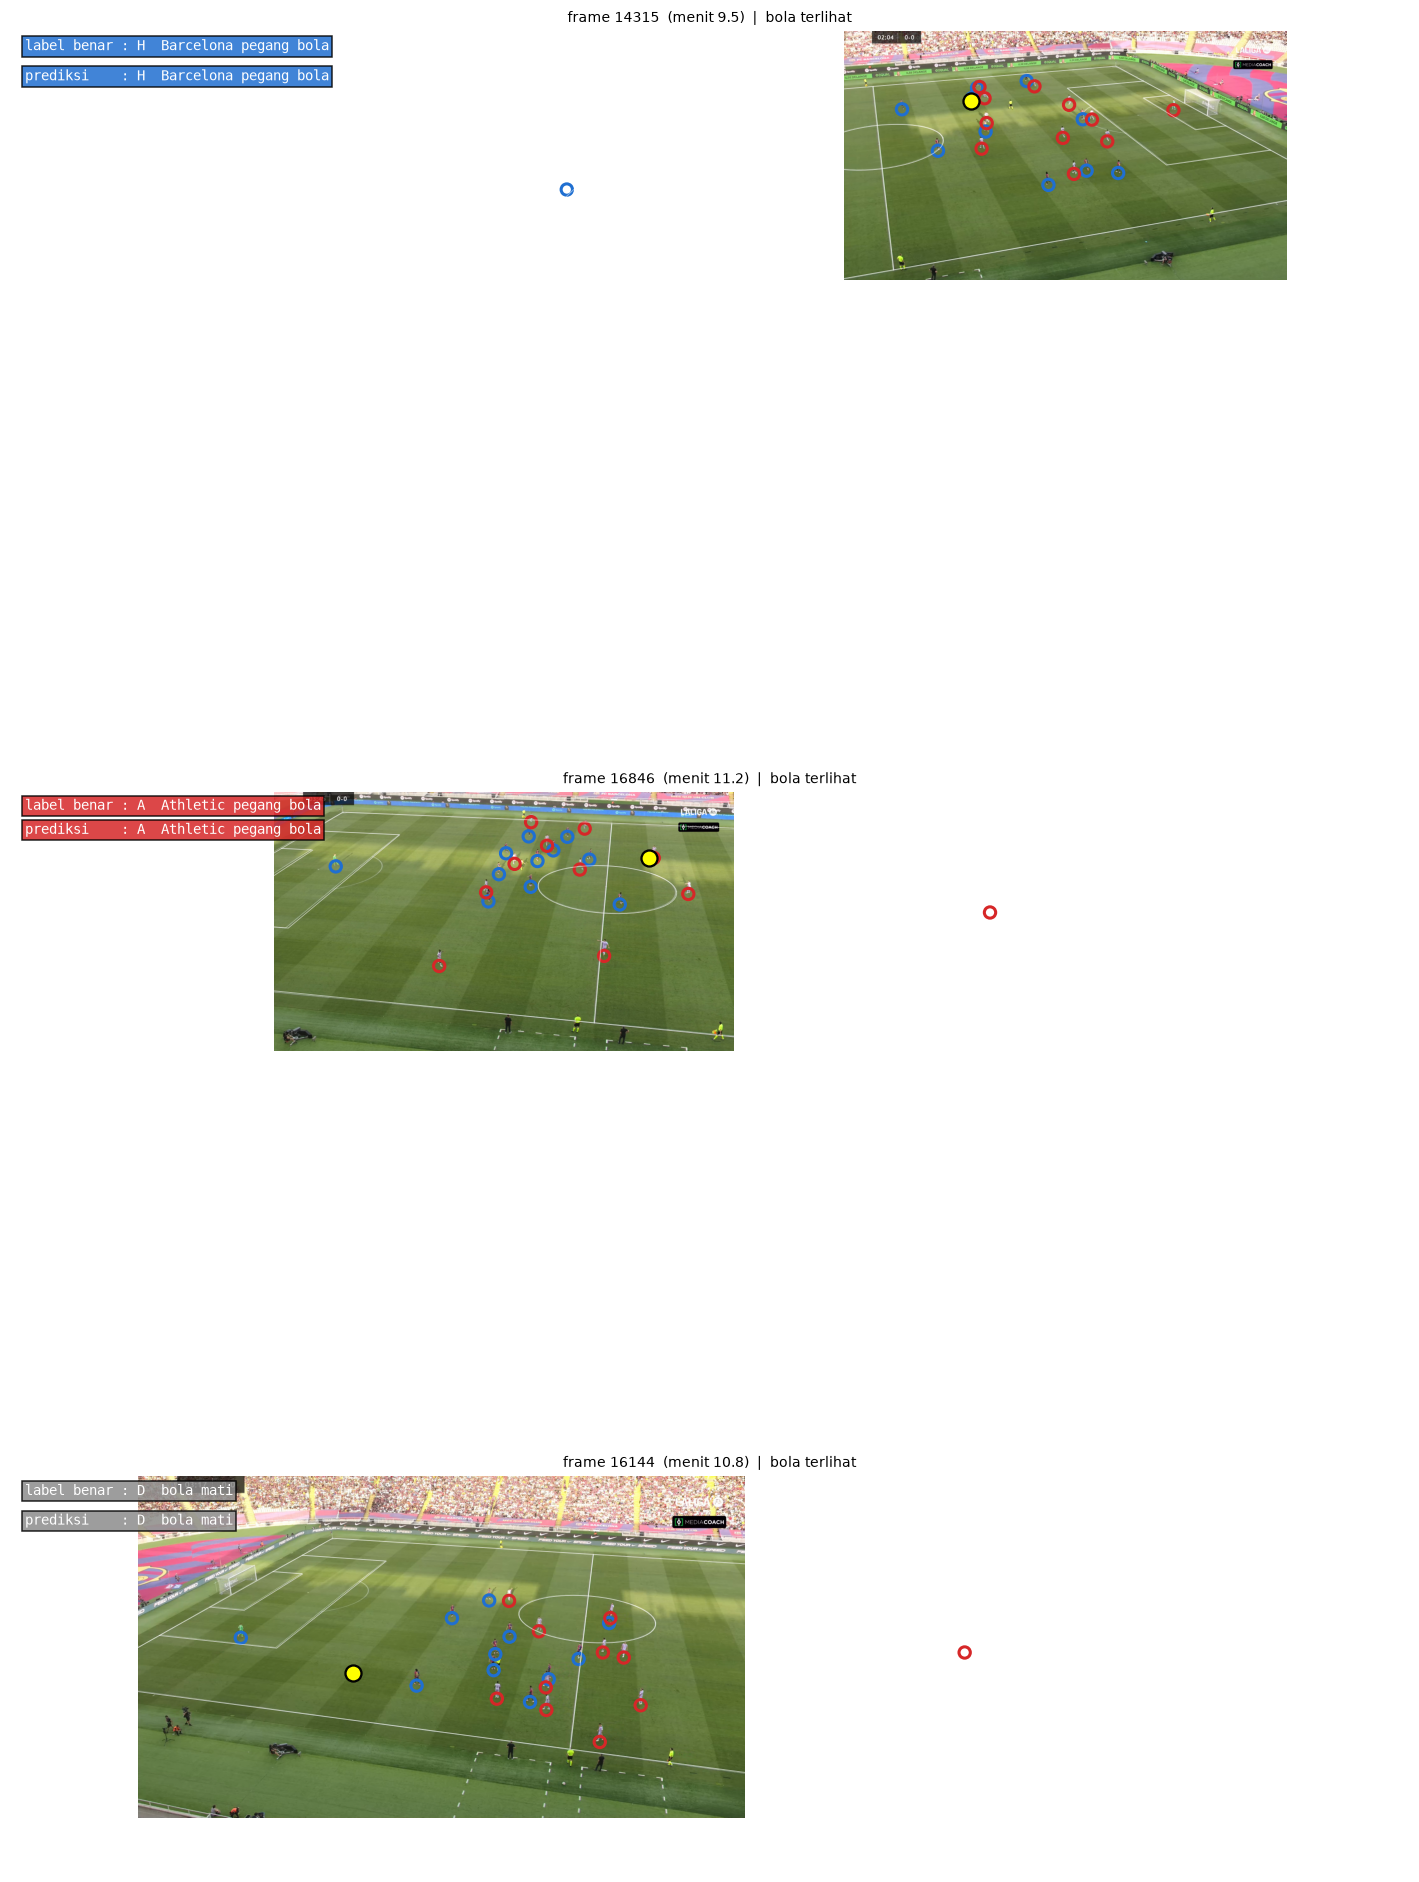

In [3]:
def runs(lab, a, b):
    lab = lab[a:b]; e = np.flatnonzero(lab[1:] != lab[:-1]) + 1
    bd = np.concatenate(([0], e, [len(lab)]))
    return [(a + s, a + t, lab[s]) for s, t in zip(bd[:-1], bd[1:])]

R = runs(gt, W0, W1)
pick = {}
for L in 'HAD':
    s, t, _ = max([r for r in R if r[2] == L], key=lambda r: r[1] - r[0])
    pick[L] = (s + t) // 2
fig, axes = plt.subplots(3, 1, figsize=(13, 22))
for ax, L in zip(axes, 'HAD'):
    viz.show_frame(ax, m, pick[L], gt=gt[pick[L]], pred=pred[pick[L]])
plt.tight_layout(); plt.show()

Perhatikan: label `D` (bola mati) biasanya terlihat dari pemain yang berdiri/berjalan pelan, bola di
luar garis atau dipegang tangan, dan sering **bola tidak terdeteksi** oleh tracker.

## 3. Saat possession berpindah — urutan frame (pengganti video)

Ini pergantian possession pertama di jendela publik (dari tim satu ke tim lain).
Frame diambil tiap 0,5 detik dari 2 detik sebelum sampai 3 detik sesudah titik pergantian versi label benar.

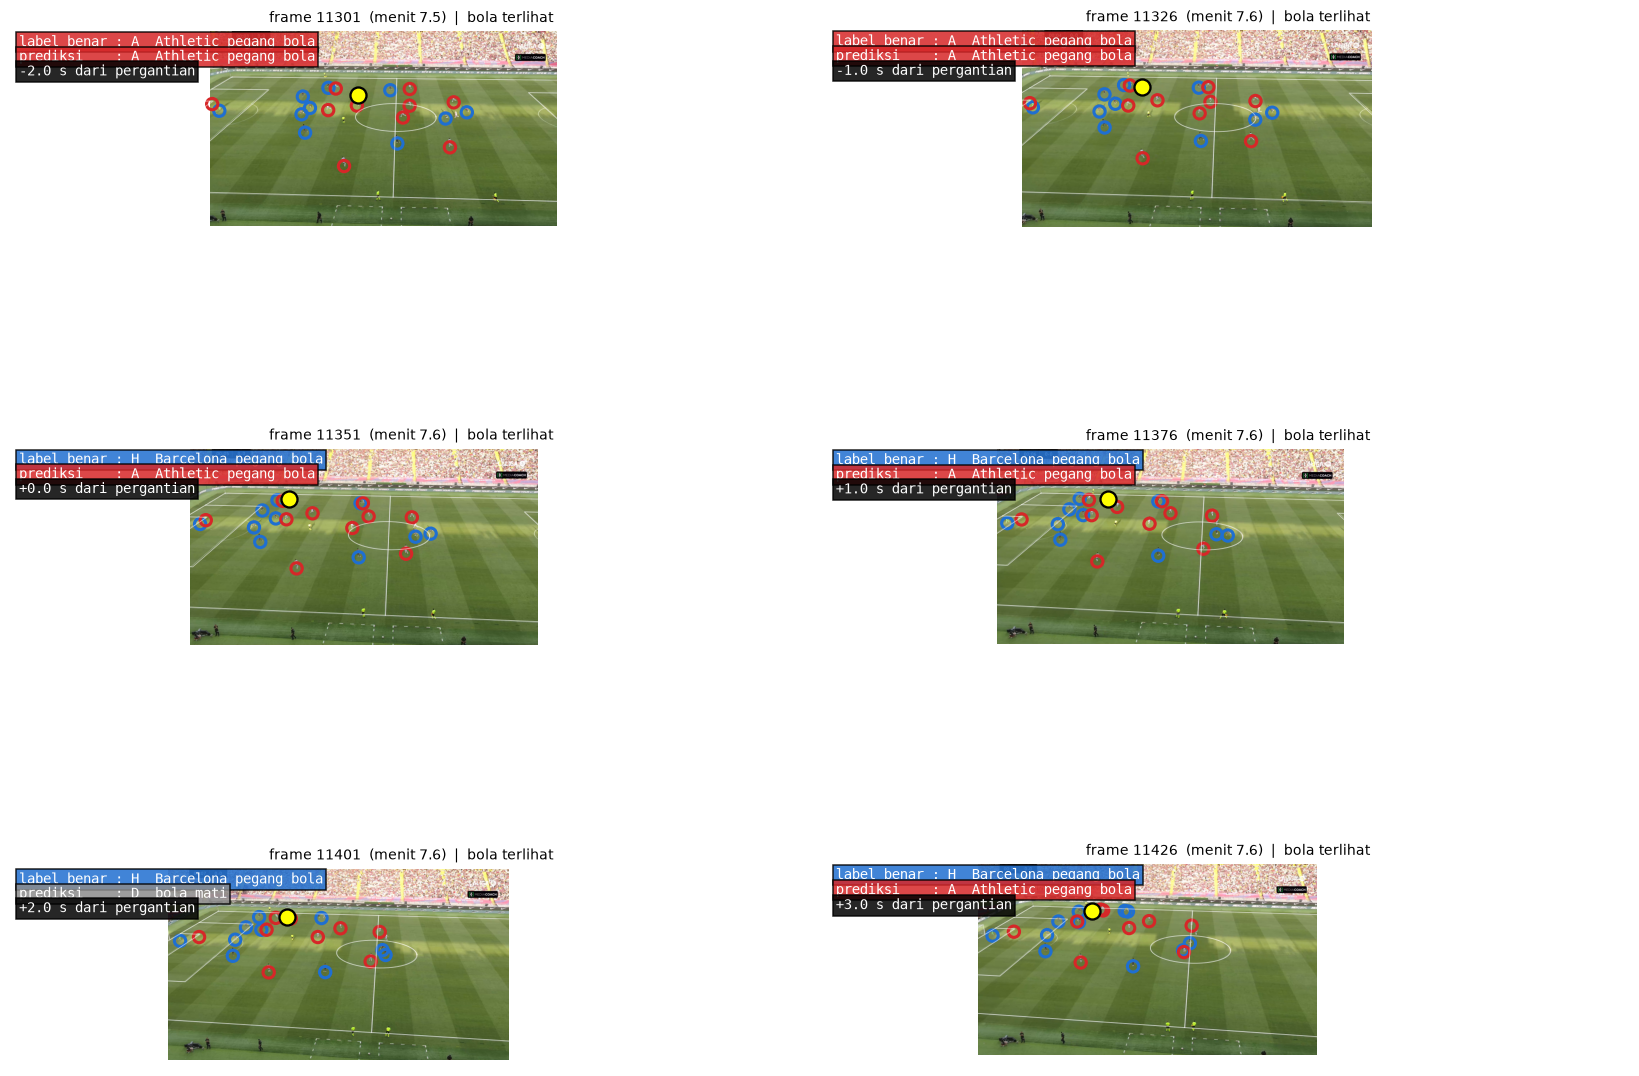

pergantian possession (label benar) di frame 11351 : A -> H


In [4]:
trans = [r[0] for k, r in enumerate(R[1:], 1) if {R[k-1][2], r[2]} == {'H', 'A'}]
t0 = trans[0]
frames = [t0 + d for d in range(-50, 76, 25)]
crop = None
fig, axes = plt.subplots(3, 2, figsize=(15, 13))
for ax, f in zip(axes.ravel(), frames):
    viz.show_frame(ax, m, f, gt=gt[f], pred=pred[f], extra='{:+.1f} s dari pergantian'.format((f - t0) / 25))
plt.tight_layout(); plt.show()
print('pergantian possession (label benar) di frame', t0, ':', gt[t0-1], '->', gt[t0])

## 4. Dari tracking → tabel fitur (seperti `test.csv` di Kaggle)

Model tidak "melihat" gambar. Ia melihat **angka yang kita hitung dari tracking**. Di bawah ini
beberapa dari ~110 kolom fitur, untuk frame-frame di bagian 3 (sudut pandang Barcelona):

In [5]:
from possession.features import team_features
from possession.tags import tag_features, smart_tagging_context
F = team_features(m, 0).join(tag_features(m.n, smart_tagging_context(), 0))
cols = {
  'ball_vis': 'bola terlihat? (1/0)',
  'dT': 'jarak pemain Barca terdekat ke bola (m)',
  'dO': 'jarak pemain Athletic terdekat ke bola (m)',
  'spd_all': 'kecepatan rata-rata semua pemain (m/s)',
  'cx_gap': 'posisi rata-rata Barca - Athletic searah serangan Barca (m)',
  'phase': 'Smart Tagging: +1 tag bilang Barca pegang, -1 Athletic',
  'until_sp': 'frame menuju set piece berikutnya (Smart Tagging)',
}
tab = F.loc[frames, list(cols)].rename(columns=cols).round(2)
tab.index.name = 'frame'
tab['LABEL BENAR (target)'] = gt[frames]
tab['prediksi'] = pred[frames]
tab.T

frame,11301,11326,11351,11376,11401,11426
bola terlihat? (1/0),1.0,1.0,1.0,1.0,1.0,1.0
jarak pemain Barca terdekat ke bola (m),9.82,6.09,3.4,8.79,8.55,4.07
jarak pemain Athletic terdekat ke bola (m),9.09,4.29,2.22,5.88,2.38,0.68
kecepatan rata-rata semua pemain (m/s),4.52,4.82,4.42,3.22,2.29,2.09
posisi rata-rata Barca - Athletic searah serangan Barca (m),-5.71,-5.13,-4.82,-4.87,-4.48,-3.29
"Smart Tagging: +1 tag bilang Barca pegang, -1 Athletic",-1.0,-1.0,-1.0,-1.0,-1.0,-1.0
frame menuju set piece berikutnya (Smart Tagging),3000.0,3000.0,3000.0,3000.0,3000.0,3000.0
LABEL BENAR (target),A,A,H,H,H,H
prediksi,A,A,A,A,D,A


Jadi masalahnya menjadi **klasifikasi tabular** biasa: baris = frame, kolom = fitur, target = H/A/D.
Bedanya dengan Kaggle: kita **tidak diberi `train.csv`** untuk pertandingan ini.

## 5. Dari mana data latih (train)?

Aturan: **tidak boleh** melabel pertandingan ini secara manual, dan label 5 menit publik tidak boleh
dipakai untuk training. Tapi data dari **pertandingan lain boleh**.

Kita pakai 3 pertandingan publik Metrica (`reference/sample-data`). Pertandingan-pertandingan ini
punya **event data** (catatan manusia: operan, bola keluar, lemparan ke dalam, dst). Dari event itu
label H/A/D per frame diturunkan otomatis:

- setelah tim X mengoper / merebut bola → `X` menguasai bola
- dari bola keluar / pelanggaran sampai set piece diambil → `D`

In [6]:
s1 = load_metrica_sample(1)
ev = sample_events(1)
print('Potongan event data Sample Game 1 (frame = 25 per detik):')
# jendela ~70 detik di sekitar bola keluar pertama, supaya H, A dan D semuanya muncul
a = int(ev[ev.type == 'BALL OUT'].start.iloc[0]) - 1200; b = a + 1800
show = ev[(ev.start > a) & (ev.start < b)].copy()
show['tim'] = np.where(show.team == 0, 'Home', 'Away')
show[['start', 'end', 'tim', 'type', 'subtype']].tail(20)

Potongan event data Sample Game 1 (frame = 25 per detik):


,start,end,tim,type,subtype
11,453,497,Away,BALL LOST,HEAD-INTERCEPTION
12,497,497,Away,CHALLENGE,AERIAL-LOST
13,498,498,Home,CHALLENGE,AERIAL-WON
14,498,498,Home,RECOVERY,INTERCEPTION
15,498,536,Home,PASS,HEAD
16,536,556,Home,PASS,
17,572,616,Home,BALL LOST,INTERCEPTION
18,618,618,Away,RECOVERY,INTERCEPTION
19,763,784,Away,PASS,
20,784,804,Away,PASS,


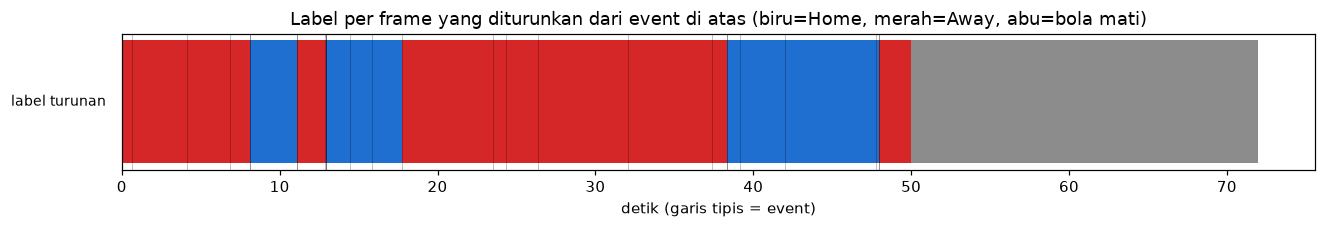

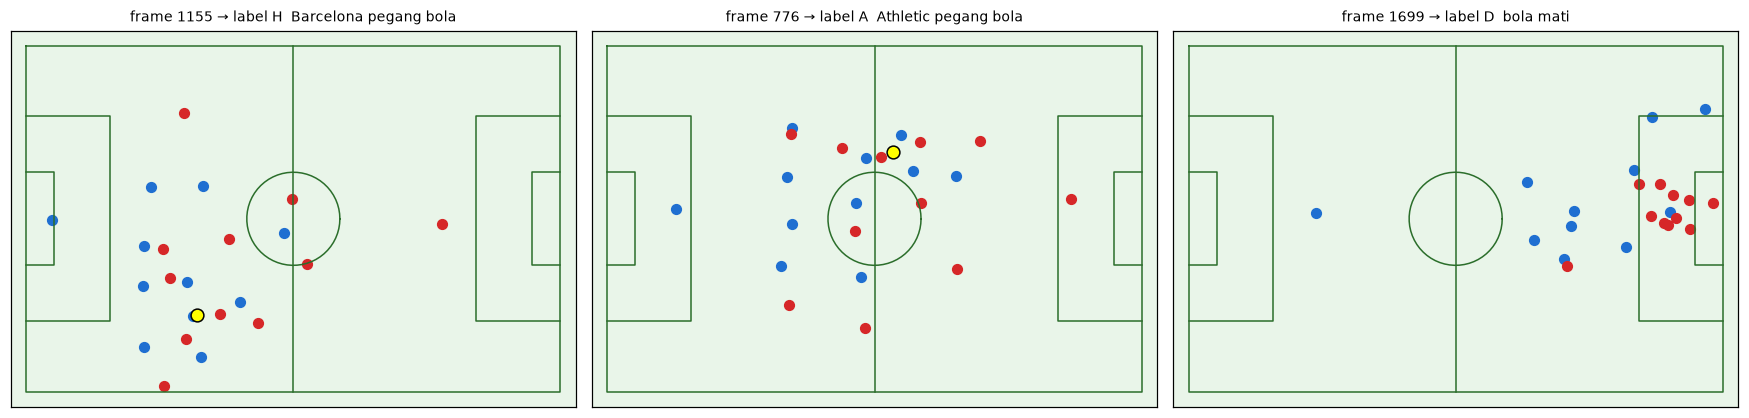

In [7]:
lab1 = np.array(list('HADX'))[s1.labels]
fig, ax = plt.subplots(figsize=(14, 1.6))
viz.label_strip(ax, lab1, a, b, name='label turunan')
for _, r in show.iterrows():
    ax.axvline((r.start - 1 - a) / 25, color='k', lw=0.4, alpha=0.4)
ax.set_yticks([]); ax.set_xlabel('detik (garis tipis = event)')
ax.set_title('Label per frame yang diturunkan dari event di atas (biru=Home, merah=Away, abu=bola mati)')
plt.show()

# satu frame per label di game latih (tanpa video, tapi tracking digambar di lapangan)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, L in zip(axes, 'HAD'):
    idx = np.flatnonzero(lab1[a:b] == L)
    f = a + idx[len(idx) // 2] if len(idx) else int(np.flatnonzero(lab1 == L)[1000])
    viz.draw_pitch(ax)
    for t, c in ((0, viz.COLORS['H']), (1, viz.COLORS['A'])):
        sel = s1.team == t
        ax.scatter(s1.px[f, sel], s1.py[f, sel], s=40, c=c)
    ax.scatter([s1.bx[f]], [s1.by[f]], s=70, c='yellow', edgecolor='k', zorder=5)
    ax.set_title('frame {} → label {}'.format(f, viz.NAMES[L]), fontsize=9)
plt.tight_layout(); plt.show()

**Masalah domain:** tracking sample ini bersih (sudah dikoreksi manusia), sedangkan tracking BAR-ATH
kotor (bola hilang 41%). Maka sebelum training, data sample **sengaja dirusak** agar mirip BAR-ATH
(`possession/features.py: degrade`). Di bawah: frame yang sama, sebelum vs sesudah dirusak.

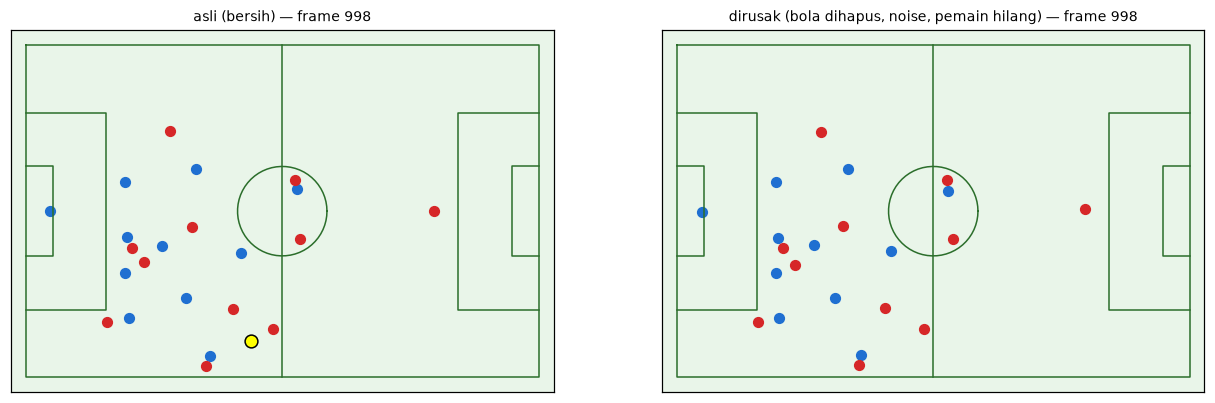

bola terlihat: asli 61%  |  setelah dirusak 58%  |  BAR-ATH 59%


In [8]:
from possession.features import degrade, run_lengths
vis, miss = run_lengths(np.isfinite(m.bx[m.period > 0]))
d1 = degrade(s1, vis, miss, np.random.default_rng(1))
lost = np.flatnonzero(~np.isfinite(d1.bx[a:b]))
f = a + (lost[len(lost)//2] if len(lost) else 0)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, mm, t in ((axes[0], s1, 'asli (bersih)'), (axes[1], d1, 'dirusak (bola dihapus, noise, pemain hilang)')):
    viz.draw_pitch(ax)
    for tm, c in ((0, viz.COLORS['H']), (1, viz.COLORS['A'])):
        ax.scatter(mm.px[f, mm.team == tm], mm.py[f, mm.team == tm], s=40, c=c)
    if np.isfinite(mm.bx[f]): ax.scatter([mm.bx[f]], [mm.by[f]], s=70, c='yellow', edgecolor='k')
    ax.set_title(t + ' — frame {}'.format(f), fontsize=9)
plt.show()
print('bola terlihat: asli {:.0%}  |  setelah dirusak {:.0%}  |  BAR-ATH {:.0%}'.format(
    np.isfinite(s1.bx).mean(), np.isfinite(d1.bx).mean(), np.isfinite(m.bx[m.period>0]).mean()))

Lalu skornya didapat seperti **cross-validation**: latih di 2 game, tebak game ke-3, bandingkan dengan
labelnya, ulangi 3× (`python -m possession.validate`).

## 6. Kenapa butuh Viterbi, dan bagaimana metrik menilai

Model memberi **probabilitas per frame**. Kalau kita ambil tebakan terbaik per frame begitu saja,
labelnya "berkedip" (H H A H H D H ...) dan satu possession pecah jadi banyak potongan.
Metrik ranking (`spellF1`) menghitung **possession utuh**, jadi kedipan itu fatal.

Viterbi mencari urutan label terbaik dengan **denda setiap kali label berganti**, sehingga hasilnya
blok-blok panjang. Bandingkan di jendela 5 menit publik:

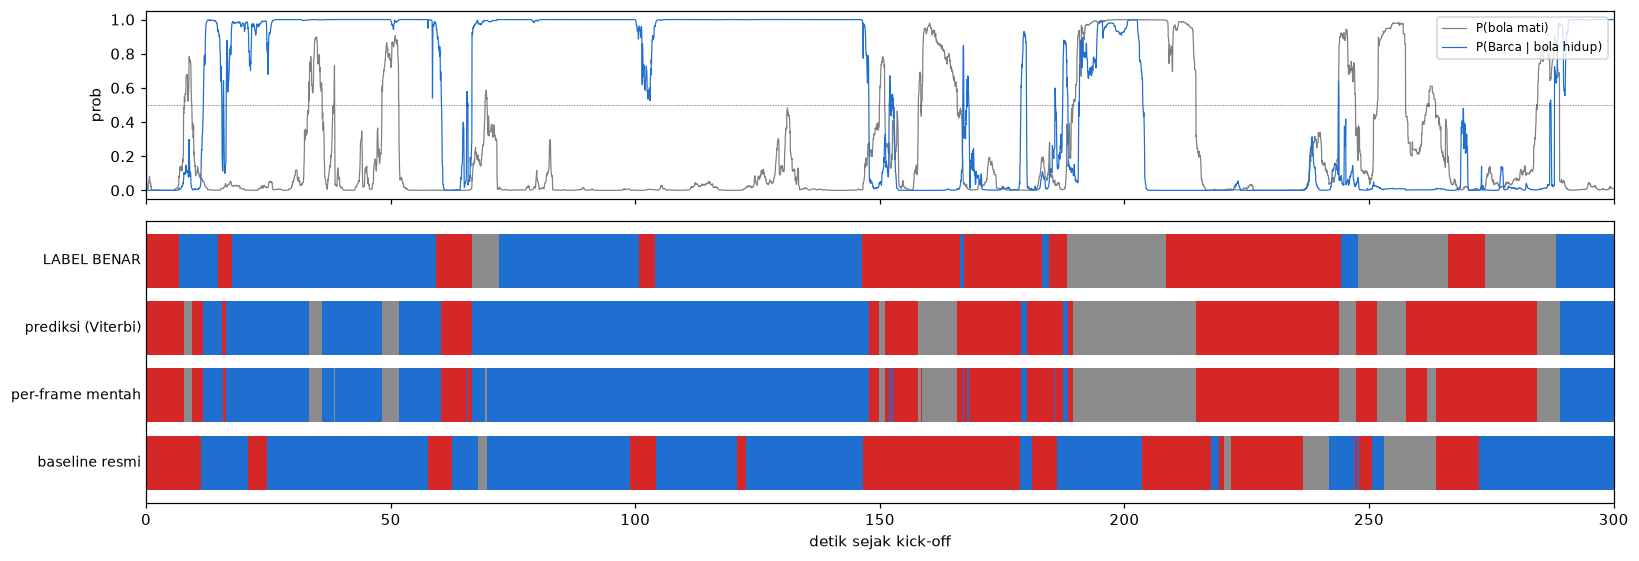

,versi,possession ditebak,possession benar,spellF1,macroF1,akurasi per frame
0,per-frame mentah,49,17,0.194,0.713,0.759
1,prediksi (Viterbi),20,17,0.346,0.705,0.756
2,baseline resmi,26,17,0.326,0.621,0.713


In [9]:
pD, pH = probs['pD'], probs['pH']
raw = np.where(pD > 0.5, 'D', np.where(pH > 0.5, 'H', 'A'))
fig, (ax0, ax1) = plt.subplots(2, 1, figsize=(15, 5.2), gridspec_kw=dict(height_ratios=[2, 3]), sharex=True)
t = (np.arange(W0, W1) - W0) / 25
ax0.plot(t, pD[W0:W1], color='gray', lw=0.8, label='P(bola mati)')
ax0.plot(t, pH[W0:W1], color=viz.COLORS['H'], lw=0.8, label='P(Barca | bola hidup)')
ax0.axhline(0.5, color='k', lw=0.4, ls=':'); ax0.legend(loc='upper right', fontsize=8); ax0.set_ylabel('prob')
for k, (lab, name) in enumerate([(gt, 'LABEL BENAR'), (pred, 'prediksi (Viterbi)'),
                                 (raw, 'per-frame mentah'), (base, 'baseline resmi')]):
    viz.label_strip(ax1, lab, W0, W1, y=-k, name=name)
ax1.set_yticks([]); ax1.set_xlabel('detik sejak kick-off'); ax1.set_xlim(0, (W1 - W0) / 25)
plt.tight_layout(); plt.show()

code = {'H': 0, 'A': 1, 'D': 2, 'X': 3}
g = np.array([code[x] for x in gt]); runs_ = pm.valid_runs(g)
rows = []
for name, lab in [('per-frame mentah', raw), ('prediksi (Viterbi)', pred), ('baseline resmi', base)]:
    p = np.array([code[x] for x in lab]); p[g == 3] = 3
    sp = pm.spell_scores(g, pm.fill_abstentions(p, runs_), runs_)
    rows.append([name, sp['n_pred'], sp['n_gt'], round(sp['mean_f1'], 3),
                 round(pm.macro_f1(pm.scored_confusion(pm.confusion(g, p))), 3),
                 round(float(np.mean(p[g < 3] == g[g < 3])), 3)])
pd.DataFrame(rows, columns=['versi', 'possession ditebak', 'possession benar', 'spellF1', 'macroF1', 'akurasi per frame'])

Cara baca tabel:
- **akurasi per frame** bisa tinggi meski possession-nya pecah-pecah.
- **spellF1** (yang dipakai ranking) menghitung possession yang tertebak *utuh* dengan awal & akhir yang
  cukup pas (overlap ≥ 30–70%).
- Ingat: jendela ini hanya 17 possession, jadi angka di sini **hanya sanity check**, bukan untuk memilih model.

## 7. Klip video dengan label

Klip ~40 detik di sekitar pergantian possession tadi, label benar & prediksi ditulis di pojok kiri atas.
Disimpan ke `data/cache/` (folder yang di-gitignore). Kalau video tidak tampil di editor kamu, buka
file mp4-nya langsung.

In [10]:
from IPython.display import Video
clip = viz.make_clip(m, t0 - 500, t0 + 500, gt, pred, os.path.join(ROOT, 'data', 'cache', 'klip_transisi.mp4'))
print(clip)
Video(clip, embed=False, width=900)

/home/reinsensilitonga/Documents/more-than-a-hack-2027-leicester-2016/data/cache/klip_transisi.mp4


Ingin klip lain? Ganti `start`/`stop` (nomor frame). Jendela berlabel publik = frame 11185–18684.
Di luar itu label benar = `X` (tidak diketahui), tapi prediksi tetap bisa dilihat:

```python
viz.make_clip(m, 50000, 51000, gt, pred, 'data/cache/klip_50000.mp4')
```